# Parallel bouquets: the five slices of an IMAS data dictionary

Each bouquet is independent, so many bouquets run in parallel, **one
single-threaded solver per worker process** (OpenFUSION's environment is a
per-process singleton). `bq.parallel_cases` takes a list of cases (a source,
an output header and a scan key each), runs them on a pool of workers that
keep their solver between cases, and merges the per-case archives.

Here the cases are the five slices of the synthetic data dictionary
(`tests/data/dd_synthetic.json.gz`: 0.7 s mid-ramp L-mode, 1.1 s L-H
transition, 1.2 s pedestal forming, 1.4 s peak pedestal, 3.0 s flat top), each
on the dd's own kinetics and σ (the `fuse` route), each drawn until 24 draws
are in spec. They merge into one archive with one scan key per slice (the
time in ms).

**Layout:** (1) the cases, (2) the sweep, (3) the merged archive, (4) the
SLURM route for a cluster, (5) error bars per slice.

> **Runtime.** Roughly 40 solves of 1-2 min per slice; with W workers the
> sweep takes about (5 x 40 / W) solves of wall time. A slice whose draws are
> all rejected stops at `max_total_draws` (5 x the target) and is reported,
> not hidden.


In [1]:
import os
import bouquet as bq
bq.add_oft_to_path()          # OFT_PYTHONPATH, known install locations or a sibling checkout
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 72})

DATA = os.path.abspath(os.path.join("..", "..", "tests", "data"))   # the synthetic fixtures
MESH = bq.find_mesh()          # the TokaMaker mesh (BOUQUET_MESH, else the one shipped in examples/)
# until-N: keep drawing until this many draws are IN SPEC (the coil test + the boundary cut).
# 24 is the default for every example; use 30 for 5/95 bands, 50 for paper-quality widths.
N_INSPEC = int(os.environ.get("BOUQUET_EXAMPLE_N_INSPEC", 24))   # (the variable is a smoke-test override)

import gzip, shutil, tempfile
DD = os.path.join(tempfile.gettempdir(), "bouquet_dd_synthetic.json")
with gzip.open(os.path.join(DATA, "dd_synthetic.json.gz"), "rb") as fi, open(DD, "wb") as fo:
    shutil.copyfileobj(fi, fo)
TIMES = [0.7, 1.1, 1.2, 1.4, 3.0]                              # the dd's five slices [s]
# workers: one single-threaded solver each (about 1 GB of RAM per worker)
N_WORKERS = int(os.environ.get("BOUQUET_EXAMPLE_WORKERS", min(4, os.cpu_count())))
print("bouquet", bq.__version__, "| until-N target:", N_INSPEC, "| workers:", N_WORKERS)

bouquet 1.4.0 | until-N target: 24 | workers: 4


## 1. The cases

One run-level config (solver, uncertainty, generation), and one `CaseSpec`
per slice: the source at that time, the output header, the scan key (ms) and
the merge group (all five in one archive).


In [2]:
template = bq.Bouquet.from_imas(DD, mesh=MESH, time=TIMES[0], n_draws=N_INSPEC, header="synthetic")
cfg = template.config
cfg.generation.n_inspec_target = N_INSPEC
cfg.generation.seed = 20261015      # base seed; each case runs at parallel.case_seed(base, case)
cases = [bq.CaseSpec(source=bq.ImasSource(**{**vars(cfg.source), "time": t}),
                     header=f"dd_t{int(round(1e3 * t)):04d}", scan_key=int(round(1e3 * t)),
                     group="dd_slices")
         for t in TIMES]
for c in cases:
    print(f"  {c.header}: time {c.source.time} s -> scan/{c.scan_key}/ of the merged archive (group {c.group!r})")

  dd_t0700: time 0.7 s -> scan/700/ of the merged archive (group 'dd_slices')
  dd_t1100: time 1.1 s -> scan/1100/ of the merged archive (group 'dd_slices')
  dd_t1200: time 1.2 s -> scan/1200/ of the merged archive (group 'dd_slices')
  dd_t1400: time 1.4 s -> scan/1400/ of the merged archive (group 'dd_slices')
  dd_t3000: time 3.0 s -> scan/3000/ of the merged archive (group 'dd_slices')


## 2. The sweep

`parallel_cases` spawns the workers, runs every case (`prepare_baseline` ->
`generate` -> `filter` on a standing solver) and merges the successful ones;
a failed case is recorded in the merged archive as a refused scan, never
dropped. Worker output goes to `worker_N.log` in the working directory.


In [3]:
import time
WORK = "synthetic_dd_sweep"
t0 = time.perf_counter()
res = bq.parallel_cases(cases, cfg, WORK, n_cpus_override=N_WORKERS, overwrite=True)
print(f"{res['n_success']}/{res['n_runs']} cases in {(time.perf_counter() - t0) / 60:.1f} min "
      f"on {N_WORKERS} workers")
for i, r in sorted(res["results"].items()):
    print(f"  {r['group']}/{r['scan_key']}: {r['n_sel']} in spec of {r['n_all']} stored  "
          f"(l_i target {r['l_i_target']:.3f})")
for i, e in res["errors"].items():
    print("  FAILED case", i, str(e)[:300])
MERGED = res["merged"]["dd_slices"]
print("merged archive:", os.path.relpath(MERGED))

[parallel_cases] 5 case(s) on 4 worker(s)


[parallel_cases] case 0 (dd_slices/700) done: 24/27 in spec


[parallel_cases] case 1 (dd_slices/1100) done: 24/25 in spec


[parallel_cases] case 2 (dd_slices/1200) done: 24/25 in spec


[parallel_cases] case 3 (dd_slices/1400) done: 24/26 in spec


[parallel_cases] case 4 (dd_slices/3000) done: 24/30 in spec


[parallel_cases] 5/5 case(s) succeeded


5/5 cases in 115.9 min on 4 workers
  dd_slices/700: 24 in spec of 27 stored  (l_i target 0.744)
  dd_slices/1100: 24 in spec of 25 stored  (l_i target 0.883)
  dd_slices/1200: 24 in spec of 25 stored  (l_i target 0.856)
  dd_slices/1400: 24 in spec of 26 stored  (l_i target 0.744)
  dd_slices/3000: 24 in spec of 30 stored  (l_i target 0.741)
merged archive: synthetic_dd_sweep/synthetic_dd_slices.h5


## 3. The merged archive

One archive, one scan key per slice. The standard readers work on it, and
`plot_bouquet_timeseries` overlays the slices.


scan 700: 27 stored, 24 in spec
scan 1100: 25 stored, 24 in spec
scan 1200: 25 stored, 24 in spec
scan 1400: 26 stored, 24 in spec
scan 3000: 30 stored, 24 in spec


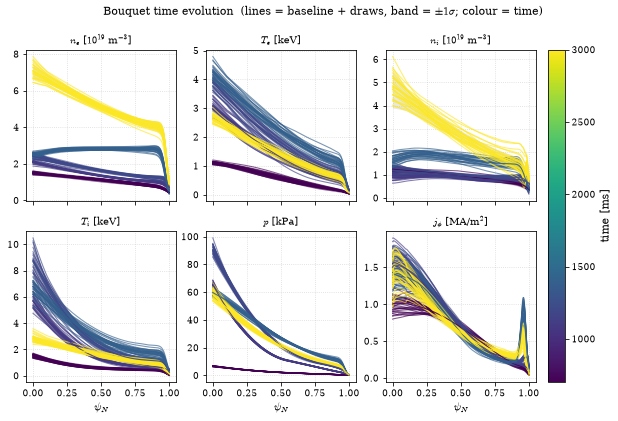

In [4]:
ar = bq.BouquetArchive(MERGED)
for k in ar.scan_keys:
    s = ar[k]
    print(f"scan {k}: {len(s.indices)} stored, {len(s.selected)} in spec"
          + (f"   (refused: {s.refused_reason})" if s.refused_reason else ""))
bq.plot_bouquet_timeseries({int(k): MERGED for k in ar.scan_keys if len(ar[k].selected)},
                           selection="selected", time_label="time [ms]"); plt.show()

## 4. On a cluster

The same sweep runs as a SLURM job array through the work queue of
`bouquet.units` (one job per node, cases claimed atomically); for the draws of
ONE large bouquet across many cores there is `parallel_generate(...,
backend="slurm")`, which writes the job-array and merge scripts without
running anything:


In [5]:
paths = bq.parallel_generate(cfg, n_workers=32, threads_per_worker=1, seed=20261015, backend="slurm",
                             slurm=dict(out_dir=tempfile.mkdtemp(), job_name="bouquet_t1200",
                                        partition=None, time_limit="02:00:00", mem_per_task="4G",
                                        python="python"))
print("wrote:", *[os.path.basename(p) for p in paths.values()])

wrote: bouquet_t1200_bundle.json bouquet_t1200_array.sbatch bouquet_t1200_merge.sbatch bouquet_t1200_submit.sh


## Error bars

One call per archive slice: `bq.bands_summary` gives, per quantity, the
**median, the 16-84 % band, the full range and n over the in-spec draws**
(the standard recipe of `bouquet.stats`: the population is the draws the
stamped filters select, nothing is filtered on, the baseline is overlaid,
never the centre). The gradients `dp_dpsi` and `djphi_dpsi` are
d/dψ_N of each draw's own archived pressure and j_φ, evaluated on each draw
at **its own q = 2 surface** (located from that draw's archived q profile);
draws without a q = 2 surface are counted and excluded, and if none has one
the helper falls back to ψ_N = 0.5 and says so in the record. Every record
carries the counts at each stage, the dropped draws with their reasons and the
limitations (`summary[q].provenance`).


Error bars over the in-spec draws of scan '700': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 11 of 24 draws (13 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N           0.1739       0.1688       0.1796       0.1653        0.182    24  
l_i_3            0.7382       0.6993       0.7721       0.6659       0.7931    24  
Lambda           0.4725       0.4514       0.4889       0.4387       0.4966    24  
dp_dpsi           -9267   -1.103e+04        -8789   -1.276e+04        -7131    11  Pa/psi_N  below_floor,gated
djphi_dpsi   -8.418e+05   -1.027e+06   -5.571e+05   -1.449e+06   -1.455e+05    11  A m^-2/psi_N  below_floor,gated



Error bars over the in-spec draws of scan '1100': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N            1.045        1.017        1.083       0.9909        1.118    24  
l_i_3            0.8971       0.8498       0.9422       0.7859        1.003    24  
Lambda            1.031        1.013        1.041       0.9982        1.052    24  
dp_dpsi      -2.133e+04   -2.286e+04   -2.027e+04   -3.359e+04   -1.932e+04    24  Pa/psi_N
djphi_dpsi   -1.783e+06    -1.92e+06   -1.564e+06   -2.044e+06   -1.358e+06    24  A m^-2/psi_N



Error bars over the in-spec draws of scan '1200': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N            1.637        1.601        1.676        1.558        1.744    24  
l_i_3            0.8424       0.7998        0.899       0.7738        0.935    24  
Lambda            1.345        1.322        1.357        1.297        1.373    24  
dp_dpsi      -5.567e+04   -6.363e+04   -4.925e+04    -6.95e+04   -4.595e+04    24  Pa/psi_N
djphi_dpsi   -1.706e+06    -1.99e+06   -1.592e+06   -2.201e+06   -1.401e+06    24  A m^-2/psi_N



Error bars over the in-spec draws of scan '1400': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N            1.738        1.681        1.777         1.63         1.84    24  
l_i_3            0.7472       0.6971       0.7905       0.6522       0.8485    24  
Lambda             1.33        1.317        1.351        1.294        1.385    24  
dp_dpsi      -5.556e+04   -5.916e+04   -4.965e+04   -6.133e+04   -4.278e+04    24  Pa/psi_N
djphi_dpsi   -1.874e+06   -2.042e+06   -1.649e+06   -2.329e+06   -1.265e+06    24  A m^-2/psi_N



Error bars over the in-spec draws of scan '3000': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N             1.41        1.376        1.478        1.335        1.562    24  
l_i_3            0.7293       0.6986       0.7685       0.6703       0.7999    24  
Lambda            1.163        1.141        1.181        1.131        1.216    24  
dp_dpsi      -5.251e+04   -5.801e+04   -4.836e+04   -6.176e+04   -4.245e+04    24  Pa/psi_N
djphi_dpsi   -1.355e+06    -1.55e+06   -1.217e+06   -1.678e+06   -1.091e+06    24  A m^-2/psi_N



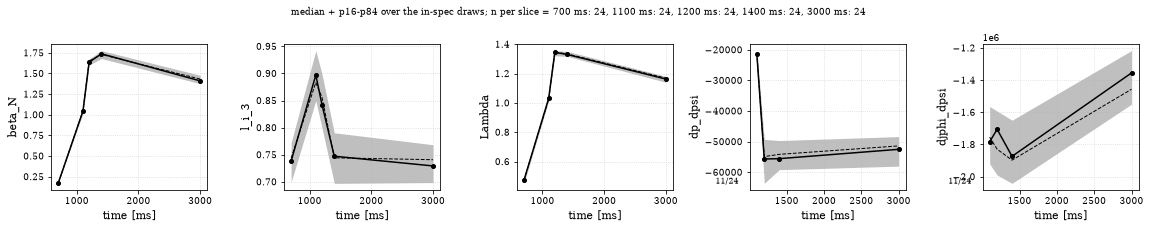

In [6]:
summaries = {}
for k in ar.scan_keys:
    summaries[k] = bq.bands_summary(MERGED, k, scalars=("beta_N", "l_i_3", "Lambda"),
                                    gradients=("dp_dpsi", "djphi_dpsi"), at={"q": 2.0},
                                    fallback_psi_N=0.5)
    print(summaries[k].table()); print()

# one band figure: every quantity against the slice time, n per slice in the title
quantities = list(next(iter(summaries.values())).records)
table = bq.BandTable([s[q] for s in summaries.values() for q in quantities])
fig, axes = plt.subplots(1, len(quantities), figsize=(3.2 * len(quantities), 3.2))
for ax, q in zip(axes, quantities):
    bq.plot_band(table, q, ax=ax); ax.set_xlabel("time [ms]")
fig.suptitle("median + p16-p84 over the in-spec draws; n per slice = "
             + ", ".join(f"{k} ms: {s.n_selected}" for k, s in summaries.items()), fontsize=9)
plt.tight_layout(); plt.show()